# Практическое занятие № 5


## 1. Исходные данные

Один год содержит четыре квартала, поэтому длина сезонного цикла $l=4$.

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Значения из таблицы
export = np.array([
    4087, 4737, 5768, 6005,
    5639, 6745, 6311, 7107,
    5741, 7087, 7310, 8600,
    6975, 6891, 7527, 7971,
    5875, 6140, 6248, 6041,
    4626, 6501, 6284, 6707
], dtype=float)

l = 4
t = np.arange(1, len(export) + 1)
years = 2016 + (t - 1) // 4
quarters = (t - 1) % 4 + 1

data = pd.DataFrame({'t': t, 'Год': years, 'Квартал': quarters,
                     'Экспорт, млрд долл. США': export})
print(data.to_string(index=False))

 t  Год  Квартал  Экспорт, млрд долл. США
 1 2016        1                   4087.0
 2 2016        2                   4737.0
 3 2016        3                   5768.0
 4 2016        4                   6005.0
 5 2017        1                   5639.0
 6 2017        2                   6745.0
 7 2017        3                   6311.0
 8 2017        4                   7107.0
 9 2018        1                   5741.0
10 2018        2                   7087.0
11 2018        3                   7310.0
12 2018        4                   8600.0
13 2019        1                   6975.0
14 2019        2                   6891.0
15 2019        3                   7527.0
16 2019        4                   7971.0
17 2020        1                   5875.0
18 2020        2                   6140.0
19 2020        3                   6248.0
20 2020        4                   6041.0
21 2021        1                   4626.0
22 2021        2                   6501.0
23 2021        3                  

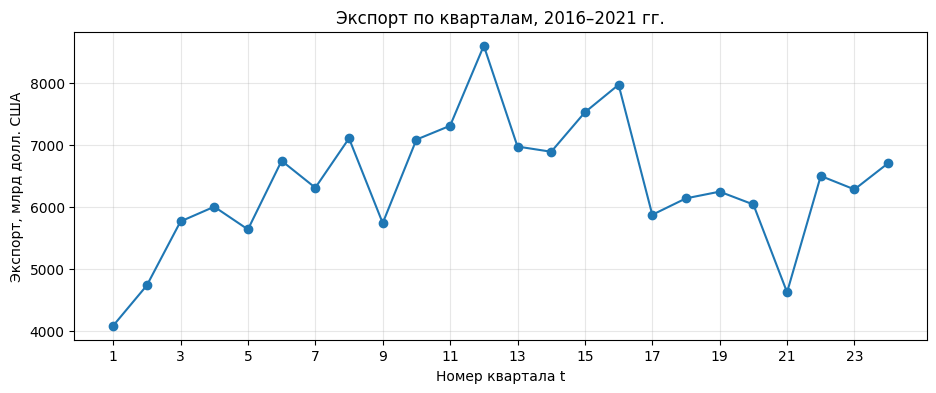

In [14]:
plt.figure(figsize=(11, 4))
plt.plot(t, export, marker='o')
plt.xticks(np.arange(1, 25, 2))
plt.xlabel('Номер квартала t')
plt.ylabel('Экспорт, млрд долл. США')
plt.title('Экспорт по кварталам, 2016–2021 гг.')
plt.grid(alpha=0.3)
plt.show()

## 2. Мультипликативная модель Хольта—Уинтерса

В мультипликативной модели сезонный эффект **умножает** уровень ряда, а не прибавляется к нему.

$$y_t = a_{1,t}f_t + \varepsilon_t,$$

где $a_{1,t}$ — уровень (базовая величина без сезонности), $f_t$ — сезонный коэффициент, $\varepsilon_t$ — случайное отклонение.

Прогноз на $\tau$ кварталов вперёд:

$$\hat y_{\tau}(t) = (\hat a_{1,t} + \tau\hat a_{2,t})\hat f_{t-l+\tau},$$

где $a_{2,t}$ — изменение уровня за квартал (тренд), $l=4$. При $f>1$ сезон увеличивает прогноз, при $f<1$ — уменьшает.

Сначала прогнозируем очередной квартал на основе предыдущих оценок, потом, зная его фактический экспорт, обновляем уровень, сезонность и тренд.

### Начальные значения

Найдем начальные уровень и тренд методом наименьших квадратов (МНК), а сезонные коэффициенты — усреднением отношений фактических значений к тренду в одинаковых кварталах.

Используем первые 8 кварталов (2016–2017 гг.) для инициализации. Оставшиеся 16 кварталов (2018–2021 гг.) используются для последовательных одноквартальных прогнозов и оценки ошибки.

In [15]:
# Начальный линейный тренд: y = a1_0 + a2_0 * t
n_start = 8
a2_0, a1_0 = np.polyfit(t[:n_start], export[:n_start], 1)
trend_start = a1_0 + a2_0 * t[:n_start]

# Средние отношения y / тренд для кварталов I, II, III, IV
f_start = np.array([
    np.mean((export[:n_start] / trend_start)[q::l])
    for q in range(l)
])

f_start = f_start / f_start.mean()

# Состояние модели на конец 8-го квартала
level_start = a1_0 + a2_0 * n_start
slope_start = a2_0

print(f'Начальный уровень на t=8: {level_start:.2f}')
print(f'Начальный тренд за квартал: {slope_start:.2f}')
for q, f in enumerate(f_start, start=1):
    print(f'Сезонный коэффициент, квартал {q}: {f:.4f}')

Начальный уровень на t=8: 7115.50
Начальный тренд за квартал: 375.89
Сезонный коэффициент, квартал 1: 0.9272
Сезонный коэффициент, квартал 2: 1.0180
Сезонный коэффициент, квартал 3: 1.0197
Сезонный коэффициент, квартал 4: 1.0351


### Подбор коэффициентов $\alpha_1$, $\alpha_2$, $\alpha_3$

Перебираем значения коэффициентов и выбираем сочетание с наименьшей **средней квадратической ошибкой (MSE)**:

$$\mathrm{MSE}=\frac{1}{m}\sum_{t=9}^{24}(y_t-\hat y_t)^2,\qquad m=16.$$

Ошибка считается только для **одноквартального прогноза, сделанного до обновления модели фактическим значением этого квартала**.

Коэффициенты сглаживания (alpha_1,alpha_2,alpha_3) подбираются перебором значений от 0,05 до 0,95 с шагом 0,05. Для каждой комбинации рассчитывается MSE по 16 одноквартальным прогнозам. Выбирается комбинация с минимальной MSE.

In [16]:

from itertools import product

def holt_winters(alpha1, alpha2, alpha3):
    a1 = level_start
    a2 = slope_start
    f = f_start.copy()
    fitted = []
    residuals = []

    # На 9-м квартале все начальные оценки уже получены из первых 8
    for i in range(n_start, len(export)):
        q = i % l  # индекс квартала от 0 до 3
        y_hat = (a1 + a2) * f[q]
        fitted.append(y_hat)
        residuals.append(export[i] - y_hat)

        # Обновление по формулам мультипликативной модели
        new_a1 = alpha1 * export[i] / f[q] + (1 - alpha1) * (a1 + a2)
        new_f = alpha2 * export[i] / new_a1 + (1 - alpha2) * f[q]
        new_a2 = alpha3 * (new_a1 - a1) + (1 - alpha3) * a2

        a1, a2 = new_a1, new_a2
        f[q] = new_f

    return np.array(fitted), np.array(residuals), a1, a2, f


# Перебор коэффициентов от 0.05 до 0.95 с шагом 0.05
values = np.arange(0.05, 1.0, 0.05)
best_mse = float('inf')
best_params = None

for alpha1, alpha2, alpha3 in product(values, repeat=3):
    fitted, residuals, _, _, _ = holt_winters(alpha1, alpha2, alpha3)
    mse = np.mean(residuals ** 2)

    if mse < best_mse:
        best_mse = mse
        best_params = (alpha1, alpha2, alpha3)

fitted, residuals, a1, a2, f = holt_winters(*best_params)

print('Оптимальные коэффициенты (на выбранной сетке):')
print(f'α1 = {best_params[0]:.2f}, α2 = {best_params[1]:.2f}, α3 = {best_params[2]:.2f}')
print(f'MSE = {best_mse:.2f} (млрд долл. США)²')

mae = np.mean(np.abs(residuals))
print(f'MAE = {mae:.2f} млрд долл. США')


Оптимальные коэффициенты (на выбранной сетке):
α1 = 0.75, α2 = 0.70, α3 = 0.15
MSE = 540149.25 (млрд долл. США)²
MAE = 562.77 млрд долл. США


## 3. Прогноз на четыре квартала 2022 года

В конце 2021 года $t=24$. Для 2022 года используем $\tau=1,2,3,4$ и последние сезонные коэффициенты для соответствующих кварталов.

In [17]:
tau = np.arange(1, l + 1)
forecast_2022 = (a1 + tau * a2) * f
forecast_table = pd.DataFrame({
    'Год': [2022] * l,
    'Квартал': tau,
    'Прогноз экспорта, млрд долл. США': np.round(forecast_2022, 2)
})
print(forecast_table.to_string(index=False))
print(f'Всего за 2022 год (сумма кварталов): {forecast_2022.sum():.2f} млрд долл. США')

 Год  Квартал  Прогноз экспорта, млрд долл. США
2022        1                           5421.62
2022        2                           6401.93
2022        3                           6448.97
2022        4                           6709.99
Всего за 2022 год (сумма кварталов): 24982.51 млрд долл. США


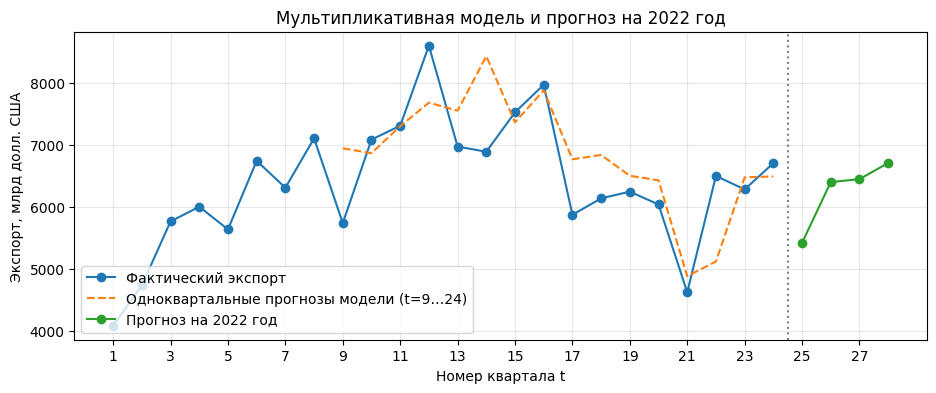

In [18]:
plt.figure(figsize=(11, 4))
plt.plot(t, export, 'o-', label='Фактический экспорт')
plt.plot(t[n_start:], fitted, '--', label='Одноквартальные прогнозы модели (t=9…24)')
plt.plot(np.arange(25, 29), forecast_2022, 'o-', label='Прогноз на 2022 год')
plt.axvline(24.5, linestyle=':', color='gray')
plt.xticks(np.arange(1, 29, 2))
plt.xlabel('Номер квартала t')
plt.ylabel('Экспорт, млрд долл. США')
plt.title('Мультипликативная модель и прогноз на 2022 год')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 4. Коррелограмма и автокорреляция

**Корреляция** показывает, насколько сильно связаны между собой два набора значений.

**Автокорреляция** показывает, насколько значения временного ряда связаны с его предыдущими значениями.

**Лаг** — это сдвиг во времени. Например, лаг 1 — сравнение соседних кварталов, лаг 4 — сравнение кварталов с разницей в один год.

Коррелограмма — график $r_\tau$ по разным лагам. для 24 наблюдений берём лаги 1–8. Посмотрим автокорреляцию исходного ряда и остатков модели (ошибок $\varepsilon_t=y_t-\hat y_t$). Если в остатках остаётся сильная автокорреляция, модель не учла часть закономерностей.

 Лаг τ  rτ исходного ряда  rτ остатков
     1              0.490       -0.036
     2              0.357       -0.236
     3              0.213       -0.068
     4              0.399        0.031
     5             -0.228       -0.036
     6             -0.213       -0.063
     7             -0.341       -0.053
     8             -0.134       -0.425


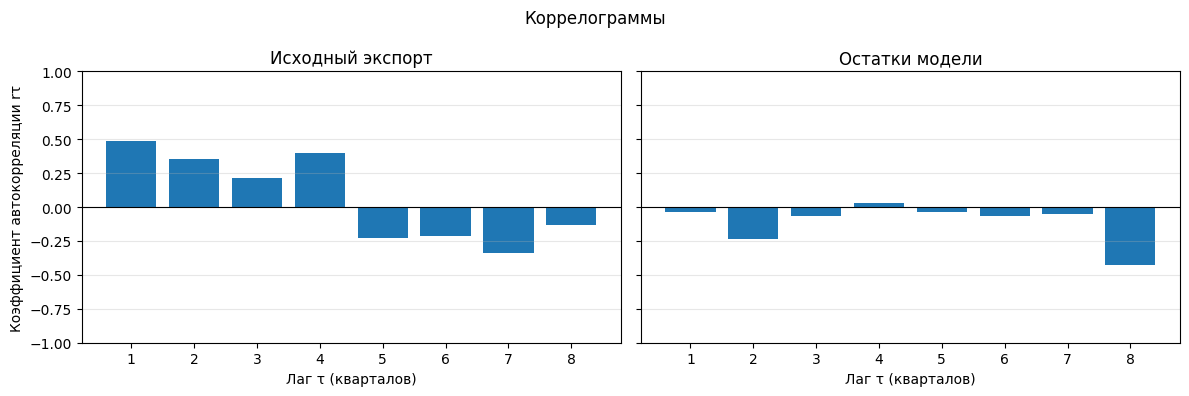

In [19]:
def autocorr_values(values, max_lag):
    return np.array([
        np.corrcoef(values[:-lag], values[lag:])[0, 1]
        for lag in range(1, max_lag + 1)
    ])

lags = np.arange(1, 9)
acf_export = autocorr_values(export, 8)
acf_residuals = autocorr_values(residuals, 8)

acf_table = pd.DataFrame({
    'Лаг τ': lags,
    'rτ исходного ряда': np.round(acf_export, 3),
    'rτ остатков': np.round(acf_residuals, 3)
})
print(acf_table.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, corr, title in zip(
    axes,
    [acf_export, acf_residuals],
    ['Исходный экспорт', 'Остатки модели']
):
    ax.bar(lags, corr)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xticks(lags)
    ax.set_ylim(-1, 1)
    ax.set_xlabel('Лаг τ (кварталов)')
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.3)
axes[0].set_ylabel('Коэффициент автокорреляции rτ')
plt.suptitle('Коррелограммы')
plt.tight_layout()
plt.show()

In [20]:
# Самые заметные автокорреляции (по абсолютному значению)
for name, values in [('Исходный ряд', acf_export), ('Остатки', acf_residuals)]:
    j = np.argmax(np.abs(values))
    print(f'{name}: наибольшая |rτ| при лаге {lags[j]}: r = {values[j]:.3f}')
print('Автокорреляция остатков при лаге 1:', round(acf_residuals[0], 3))

Исходный ряд: наибольшая |rτ| при лаге 1: r = 0.490
Остатки: наибольшая |rτ| при лаге 8: r = -0.425
Автокорреляция остатков при лаге 1: -0.036


## 5. Критерий Дарбина—Уотсона

$$d=\frac{\sum_{t=2}^{m}(\varepsilon_t-\varepsilon_{t-1})^2}{\sum_{t=1}^{m}\varepsilon_t^2},$$

где $\varepsilon_t$ — ошибки модели. У нас $m=16$ последовательных ошибок одноквартального прогноза (кварталы 9–24).

Интерпретация: значение $d$ около 2 соответствует отсутствию выраженной автокорреляции первого порядка; ближе к 0 — положительной, ближе к 4 — отрицательной.

In [22]:
d = np.sum(np.diff(residuals) ** 2) / np.sum(residuals ** 2)
print(f'Критерий Дарбина—Уотсона: d = {d:.4f}')
print(f'Автокорреляция остатков (лаг 1): r1 = {acf_residuals[0]:.4f}')

if 1.5 <= d <= 2.5:
    print('Оценка: d близок к 2; выраженная автокорреляция первого порядка не наблюдается.')
elif d < 1.5:
    print('Оценка: возможна положительная автокорреляция остатков.')
else:
    print('Оценка: возможна отрицательная автокорреляция остатков.')

Критерий Дарбина—Уотсона: d = 1.7969
Автокорреляция остатков (лаг 1): r1 = -0.0358
Оценка: d близок к 2; выраженная автокорреляция первого порядка не наблюдается.


## 6. Вывод по заданию

Построена **мультипликативная модель Хольта—Уинтерса** с длиной сезонного цикла $l=4$; коэффициенты сглаживания подобраны по минимальной MSE. Получен прогноз экспорта отдельно на каждый квартал 2022 года.

Для исходных данных и остатков построены коррелограммы и рассчитаны автокорреляции. По остаткам вычислен критерий Дарбина—Уотсона. $d$ близок к 2, а автокорреляция остатков на первом лаге мала, то явной последовательной зависимости ошибок не видно, что **поддерживает** пригодность модели для прогноза.